# News Articles Clasification 

This project aims to integrate Deep Learning with Big Data by developing a Text Classification Model to categorize news articles into topics such as sports, business, and technology.

News data is a prime example of Big Data due to its high velocity (real-time updates), high volume (millions of articles published daily), high variety (text, images, videos, and multiple languages), and veracity challenges (fake news, bias, and misinformation). Addressing these complexities requires advanced processing techniques, making deep learning a powerful tool for handling and analyzing news at scale.

Additionaly, Hadoop  ecosystem and Apache Spark framework have been implemented. Hadoop uses distributed storage and parallel processing to handle big data and analytics jobs, breaking workloads down into smaller workloads that can be run at the same time.on the other hand, Apache Spark is a system used for big data workloads. It utilizes in-memory caching, and optimized query execution for fast analytic queries against data of any size.

### Video Recording links

- Link 1:
https://drive.google.com/file/d/1s3cVnI6aA_pKB1vrduLNEpMSUz_nH92r/view?usp=sharing

- Link 2: 
https://drive.google.com/file/d/1KksNdxZxSlWRAx68J_i0gv2g3dreIvUk/view


I uploaded the practical demonstration video into 2 differents google drive acconts just in case one of them is not working. Thanks. 


Dataset Link:
https://drive.google.com/file/d/1CN6behaQ-Umhj7GBy2mrWn1zF6VgxyjU/view?usp=sharing

## Import Libraries

Necessary libraries are imported.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.functions import size, split
from pyspark.ml.feature import Tokenizer, StopWordsRemover, CountVectorizer, StringIndexer, HashingTF, IDF
from pyspark.ml.classification import MultilayerPerceptronClassifier, MultilayerPerceptronClassificationModel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
import pandas as pd


## Initialize Spark Session

In [2]:
spark = SparkSession.builder.appName("News_Classification").getOrCreate()


26/09/29 20:00:33 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


## Load the Dataset from HDSF

The dataset is been loaded from hadoop. The dataset is labeled under the CC0: Public Domain License, allowing unrestricted use.

In [5]:
df = spark.read.csv("/CA1/Events.csv", header=True, inferSchema=True)
df.show(5)

+--------------------+----------+--------------------+-----+-----------+-----------+--------------------+--------------------+----------+-------+------+--------+---------+----------------+-----+----------+--------+----------+--------+---------------+
|                Name|Event Type|         Description|Image|Contact URL|Booking URL|Contact Phone Number|Booking Phone Number|Venue Name|Address|County|Latitude|Longitude|Is Free To Visit|Price|Start Date|End Date|Start Time|End Time|Recurring Dates|
+--------------------+----------+--------------------+-----+-----------+-----------+--------------------+--------------------+----------+-------+------+--------+---------+----------------+-----+----------+--------+----------+--------+---------------+
|Jameson Christmas...|     Event|Step behind the b...| NULL|       NULL|       NULL|                NULL|                NULL|      NULL|   NULL|  NULL|    NULL|     NULL|            NULL| NULL|      NULL|    NULL|      NULL|    NULL|           NU

In [7]:
df = df[["Description", "Event Type"]].copy()

PySparkAttributeError: [ATTRIBUTE_NOT_SUPPORTED] Attribute `copy` is not supported.

## Data Processing

### Exploratory Data Analysis

#### Check Schema

In [8]:
df.printSchema()

root
 |-- Name: string (nullable = true)
 |-- Event Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Image: string (nullable = true)
 |-- Contact URL: string (nullable = true)
 |-- Booking URL: string (nullable = true)
 |-- Contact Phone Number: string (nullable = true)
 |-- Booking Phone Number: string (nullable = true)
 |-- Venue Name: string (nullable = true)
 |-- Address: string (nullable = true)
 |-- County: string (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Longitude: string (nullable = true)
 |-- Is Free To Visit: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Start Date: string (nullable = true)
 |-- End Date: string (nullable = true)
 |-- Start Time: string (nullable = true)
 |-- End Time: string (nullable = true)
 |-- Recurring Dates: string (nullable = true)



#### Data types

In [9]:
df.dtypes

[('Name', 'string'),
 ('Event Type', 'string'),
 ('Description', 'string'),
 ('Image', 'string'),
 ('Contact URL', 'string'),
 ('Booking URL', 'string'),
 ('Contact Phone Number', 'string'),
 ('Booking Phone Number', 'string'),
 ('Venue Name', 'string'),
 ('Address', 'string'),
 ('County', 'string'),
 ('Latitude', 'string'),
 ('Longitude', 'string'),
 ('Is Free To Visit', 'string'),
 ('Price', 'string'),
 ('Start Date', 'string'),
 ('End Date', 'string'),
 ('Start Time', 'string'),
 ('End Time', 'string'),
 ('Recurring Dates', 'string')]

#### Summary Statistics

In [10]:
df.describe().show()

26/09/29 20:07:50 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+-----------------+------------------+------------------+
|summary|                Name|          Event Type|         Description|               Image|         Contact URL|         Booking URL|Contact Phone Number|Booking Phone Number|          Venue Name|             Address|              County|            Latitude|           Longitude|    Is Free To Visit|               Price|          Start Date|            End Date|       Start Time|          End Time|   Recurring Dates|
+-------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+-------------------

#### Analyzing for Missing Values

In [11]:
df.filter(df["Event Type"].isNull()).show()
df.filter(df["Description"].isNull()).show()

+--------------------+----------+-----------+-----+-----------+-----------+--------------------+--------------------+----------+-------+------+--------+---------+----------------+-----+----------+--------+----------+--------+---------------+
|                Name|Event Type|Description|Image|Contact URL|Booking URL|Contact Phone Number|Booking Phone Number|Venue Name|Address|County|Latitude|Longitude|Is Free To Visit|Price|Start Date|End Date|Start Time|End Time|Recurring Dates|
+--------------------+----------+-----------+-----+-----------+-----------+--------------------+--------------------+----------+-------+------+--------+---------+----------------+-----+----------+--------+----------+--------+---------------+
|        ⏳ 60 minutes|      NULL|       NULL| NULL|       NULL|       NULL|                NULL|                NULL|      NULL|   NULL|  NULL|    NULL|     NULL|            NULL| NULL|      NULL|    NULL|      NULL|    NULL|           NULL|
|⏱️ Various times ...|      NULL

No missing values have found.

#### Count Unique Values

This shows the categories 

In [9]:
df.select("Description").distinct().show()


+--------------------+
|         Description|
+--------------------+
|https://triskelar...|
|“Ten years of The...|
|Our Shared Christ...|
|Get ready for a s...|
|Discover the haun...|
| and work togethe...|
|Buckle up for a w...|
|MIXTAPE presents ...|
|https://samhainhe...|
| experience the s...|
|https://triskelar...|
|The band had  the...|
|An exclusive Deut...|
|https://newbridge...|
| talks and the Re...|
|Sarah Long is an ...|
|The mountain form...|
|https://www.ticke...|
|The night begins ...|
|            Carmilla|
+--------------------+
only showing top 20 rows


##### Value Count for Categorical Variables

In [12]:
df.groupBy("Event type").count().orderBy("count", ascending=False).show()


+--------------------+-----+
|          Event type|count|
+--------------------+-----+
|                NULL| 8297|
|               Event| 3574|
|            Festival|  461|
|https://assets-eu...|  218|
| our walking tour...|  218|
|https://assets-eu...|  218|
| but it also set ...|  184|
|https://assets-eu...|  176|
|https://assets-eu...|  162|
| and the huge glo...|  132|
|https://assets-eu...|  132|
| and you’re free ...|  132|
|https://assets-eu...|  112|
| straight from th...|   78|
|https://assets-eu...|   78|
|                Thur|   78|
| this experience ...|   78|
|https://assets-eu...|   72|
| part of Ireland ...|   66|
|https://assets-eu...|   64|
+--------------------+-----+
only showing top 20 rows


26/09/29 20:24:39 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 906342 ms exceeds timeout 120000 ms
26/09/29 20:24:41 WARN SparkContext: Killing executors is not supported by current scheduler.
26/09/29 20:24:41 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$

26/09/29 20:24:42 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$driverEndpoint(BlockManagerMasterEndpoint.scala:131)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.isExecutorAlive$lzycompute$1(BlockManagerMasterEndpoint.scala:707)
	at org.apache.spark.storage.BlockManagerMasterE

26/09/29 20:24:42 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$driverEndpoint(BlockManagerMasterEndpoint.scala:131)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.isExecutorAlive$lzycompute$1(BlockManagerMasterEndpoint.scala:707)
	at org.apache.spark.storage.BlockManagerMasterE

26/09/29 20:24:43 WARN Executor: Issue communicating with driver in heartbeater
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:101)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:85)
	at org.apache.spark.storage.BlockManagerMaster.registerBlockManager(BlockManagerMaster.scala:81)
	at org.apache.spark.storage.BlockManager.reregister(BlockManager.scala:674)
	at org.apache.spark.executor.Executor.reportHeartBeat(Executor.scala:1530)
	at org.apache.spark.executor.Executor.$anonfun$heartbeater$1(Executor.scala:483)
	at scala.runtime.java8.JFunction0$mcV$sp.apply(JFunction0$mcV$sp.scala:18)
	at org.apache.spark.util.Utils$.logUncaughtExceptions(Utils.scala:1941

## Data Visualization

Distributions of the dataset were plotted 

#### Distribution of News by Category

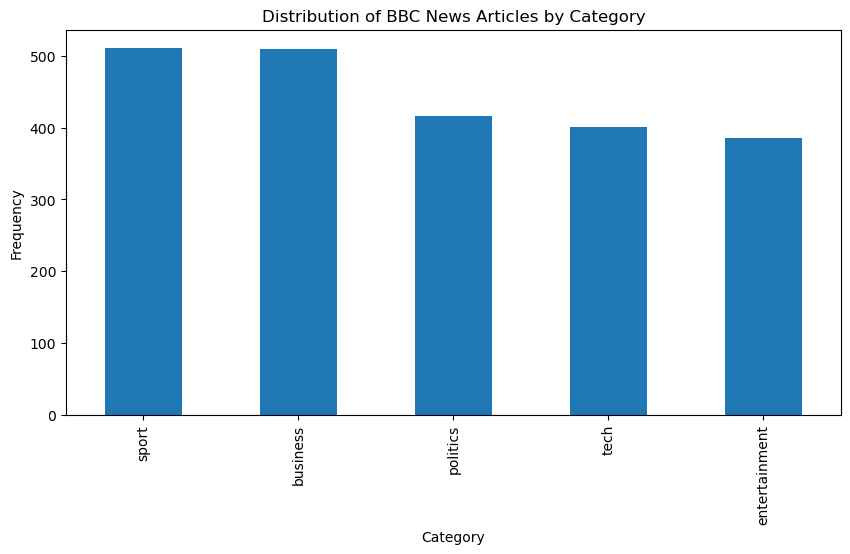

In [14]:
pandas_df = df.select("category").toPandas()
pandas_df["category"].value_counts().plot(kind="bar", figsize=(10,5))
plt.xlabel("Category")
plt.ylabel("Frequency")
plt.title("Distribution of BBC News Articles by Category")
plt.show()


#### Distribution by Words

In [15]:
# Calculate the word count for each news article
df_word = df.withColumn("word_count", size(split(df["text"], " ")))

# Show a preview
df_word.select("text", "word_count").show(5)

+--------------------+----------+
|                text|word_count|
+--------------------+----------+
|tv future in the ...|       806|
|worldcom boss  le...|       332|
|tigers wary of fa...|       270|
|yeading face newc...|       390|
|ocean s twelve ra...|       287|
+--------------------+----------+
only showing top 5 rows


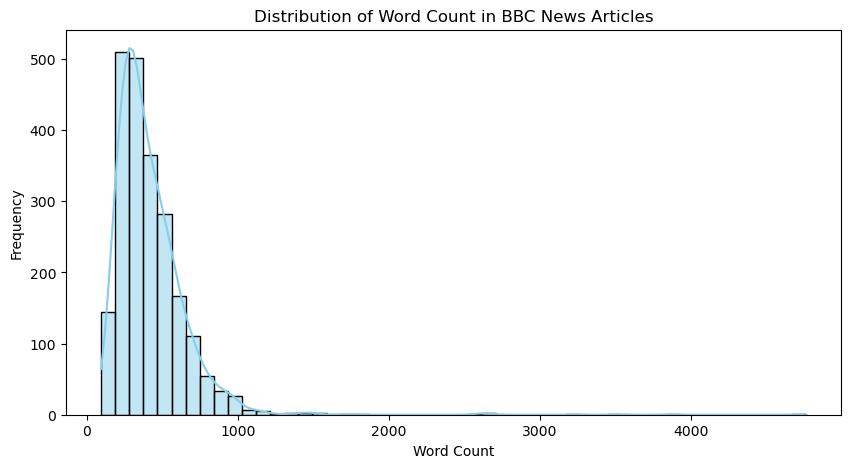

In [16]:
# Convert to Pandas for visualization
df_word_pandas = df_word.select("word_count").toPandas()

# Plot distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_word_pandas["word_count"], bins=50, kde=True, color="skyblue")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.title("Distribution of Word Count in BBC News Articles")
plt.show()

#### Boxplot

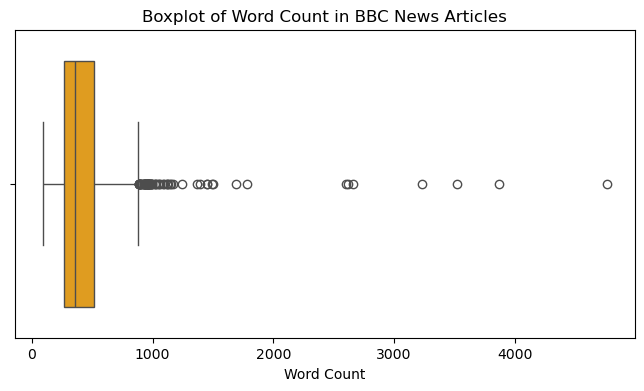

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_word_pandas["word_count"], color="orange")
plt.xlabel("Word Count")
plt.title("Boxplot of Word Count in BBC News Articles")
plt.show()

Notes: 
- Right-Skewed distribution, mostly of the articles are lower than 1000 words
- The peak is around 200 and 300 words
- Long-Tail, a small amount of aticles are longer than 1000 words

## Text Transformation and Feature Engineering

#### Tokenization
Converting the text into smaller units, known as tokens. This facilitates machines understanding and processing.

In [4]:
# Tokenizing
tokenizer = Tokenizer(inputCol="text", outputCol="words")
df_words = tokenizer.transform(df)

### Stop-Word Removal
stop words are filtered out from input text data, removing commonly used used words that do not carry significant meaning.

In [5]:
# Remove Stopwords
remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")
df_filtered = remover.transform(df_words)


### Repartitioning
the dataset was repartitioned to optimize parallel processing and resource utilization.

In PySpark, the repartition() method is used to adjust the number of partitions in a DataFrame, either increasing or decreasing them. This operation involves reshuffling the data across the cluster, which can be resource-intensive due to the required data movement.
Use Cases:

- Balancing Data Distribution: Repartitioning can help address data skew by redistributing data evenly across partitions, leading to more efficient processing.
- Optimizing Join Operations: When performing joins on large datasets, repartitioning by the join key can enhance performance by ensuring that matching keys are co-located in the same partition.

In [6]:
# Repartition data before applying transformations
df_repartitioned = df.repartition(100)  

### Word Vectorization
Tokens were converted into numerical vector using Term Frequency-Inverse Document, capturing word importance within the corpus.

In [7]:
# Convert words into numeric features using HashingTF (TF)
hashingTF = HashingTF(inputCol="filtered_words", outputCol="rawFeatures", numFeatures=500)
df_hashed = hashingTF.transform(df_filtered)

In [8]:
# Compute TF-IDF
idf = IDF(inputCol="rawFeatures", outputCol="features")
idf_model = idf.fit(df_hashed)
df_transformed = idf_model.transform(df_hashed)

### Label Encoding
Categorical labels were converted into numerical format.

In [9]:
# Convert category labels to numerical values using StringIndexer
indexer = StringIndexer(inputCol="category", outputCol="label")
df_final = indexer.fit(df_transformed).transform(df_transformed)

In [24]:
# Show final dataset with features
df_final.select("category", "label").show(6, truncate=False)


+-------------+-----+
|category     |label|
+-------------+-----+
|tech         |3.0  |
|business     |1.0  |
|sport        |0.0  |
|sport        |0.0  |
|entertainment|4.0  |
|politics     |2.0  |
+-------------+-----+
only showing top 6 rows


## Model Training and Evaluation

For this proyect the Multilayer Perceptron Classifier from Spark MLlib is used.
MLP is a type of artificial neural network consisting of multiple layers of neurons. The neurons in the MLP typically use nonlinear activation functions, allowing the network to learn complex patterns in data. 

### Data Splitting
the dataset was partitioned into 80% for training and 20% for testing.

In [10]:
# Split data into training and testing sets (80% train, 20% test)
train_data, test_data = df_final.randomSplit([0.8, 0.2], seed=42)

### Model Definition
the MLP model is configured with 500 neurons in the firs hidden layer, 150 neurons in the second hidden layer and 32 neurons in the third hidden layer.

In [11]:
# Define MLP model layers
layers = [500, 150, 32, len(df_final.select("category").distinct().collect())] 


In [12]:
# Initialize MLP Classifier
mlp = MultilayerPerceptronClassifier(featuresCol="features", labelCol="label", layers=layers, maxIter=100)


### Train the model
The model was trained on the training dataset, optimizing parameters to minimize classification error.

In [13]:
# Train the model
mlp_model = mlp.fit(train_data)

This model is been saved in Hadoop 

### Screenshot of Hadoop

We can observe that the trained model is been saved in HDFS

## Making Predictions
The trained MLP model was tested in making predictions on the test dataset.

In [14]:
# Make predictions
predictions = mlp_model.transform(test_data)

In [36]:
# Show predictions on test data
predictions.select("text", "category", "prediction").show(5, truncate=False)


+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## Accuracy
the model was evaluated by MulticlassClassificationEvaluator, achieving an accuracy of 92%.

The MulticlassClassificationEvaluator in PySpark is a utility for assessing the performance of multiclass classification models. It computes various evaluation metrics, such as accuracy, F1 score, and log loss, to gauge model effectiveness

In [15]:
# Make predictions
predictions = mlp_model.transform(test_data)


# Evaluate the model (accuracy)
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator.evaluate(predictions)

print(f"Test Accuracy: {accuracy:.2f}")


Test Accuracy: 0.92


In [46]:
import sys
print(sys.executable)
print(sys.version)


/usr/bin/python3
3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]


In [48]:
import shutil

print("python3:", shutil.which("python3"))
print("python3.12:", shutil.which("python3.12"))


python3: /usr/bin/python3
python3.12: /usr/bin/python3.12


In [25]:
import os

print("PYSPARK_PYTHON =", os.environ.get("PYSPARK_PYTHON"))
print("PYSPARK_DRIVER_PYTHON =", os.environ.get("PYSPARK_DRIVER_PYTHON"))
print("PYTHON =", os.environ.get("PYTHON"))


PYSPARK_PYTHON = /usr/local/anaconda3/bin/python3
PYSPARK_DRIVER_PYTHON = jupyter
PYTHON = None


In [23]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Test")
    .config("spark.pyspark.python", "/usr/bin/python3.12")
    .config("spark.pyspark.driver.python", "/usr/bin/python3.12")
    .getOrCreate()
)


26/09/29 17:55:07 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [26]:
import os
import sys

os.environ["PYSPARK_PYTHON"] = "/usr/bin/python3.12"
os.environ["PYSPARK_DRIVER_PYTHON"] = "/usr/bin/python3.12"

print("Python notebook:", sys.executable)
print("PYSPARK_PYTHON:", os.environ["PYSPARK_PYTHON"])
print("PYSPARK_DRIVER_PYTHON:", os.environ["PYSPARK_DRIVER_PYTHON"])


Python notebook: /usr/bin/python3
PYSPARK_PYTHON: /usr/bin/python3.12
PYSPARK_DRIVER_PYTHON: /usr/bin/python3.12


In [27]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("MyApp")
    .config("spark.pyspark.python", "/usr/bin/python3.12")
    .config("spark.pyspark.driver.python", "/usr/bin/python3.12")
    .getOrCreate()
)


26/09/29 17:56:58 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [28]:
spark.range(5).show()


+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [29]:
new_predictions.select("text", "prediction").show(truncate=False)


26/09/29 17:57:45 ERROR Executor: Exception in task 0.0 in stage 117.0 (TID 174)
org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker.py", line 3305, in main
    check_python_version(infile)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker_util.py", line 77, in check_python_version
    raise PySparkRuntimeError(
    ...<5 lines>...
    )
pyspark.errors.exceptions.base.PySparkRuntimeError: [PYTHON_VERSION_MISMATCH] Python in worker has different version: 3.14 than that in driver: 3.12, PySpark cannot run with different minor versions.
Please check environment variables PYSPARK_PYTHON and PYSPARK_DRIVER_PYTHON are correctly set.

	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator.handlePythonException(PythonRunner.scala:645)
	at org.apache.spark.api.python.PythonRunner$$anon$3.read(PythonRunner.scala:1029)
	at org.apache.spark.api.python.Py

Py4JJavaError: An error occurred while calling o1110.showString.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 117.0 failed 1 times, most recent failure: Lost task 0.0 in stage 117.0 (TID 174) (BDSP2025 executor driver): org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker.py", line 3305, in main
    check_python_version(infile)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker_util.py", line 77, in check_python_version
    raise PySparkRuntimeError(
    ...<5 lines>...
    )
pyspark.errors.exceptions.base.PySparkRuntimeError: [PYTHON_VERSION_MISMATCH] Python in worker has different version: 3.14 than that in driver: 3.12, PySpark cannot run with different minor versions.
Please check environment variables PYSPARK_PYTHON and PYSPARK_DRIVER_PYTHON are correctly set.

	at org.apache.spark.api.python.BasePythonRunner

### New Article Prediction
The model was utilized to classify new articles, it classified them correctly.


In [24]:
# New article to predict
new_article = [("Ireland won the rugby match last friday",)]  

# Convert to DataFrame
new_df = spark.createDataFrame(new_article, ["text"])

# Preprocessing the new article (tokenize, remove stopwords, TF-IDF)
new_words = tokenizer.transform(new_df)
new_filtered = remover.transform(new_words)
new_hashed = hashingTF.transform(new_filtered)
new_transformed = idf_model.transform(new_hashed)

# Predict the category using the trained model
new_predictions = mlp_model.transform(new_transformed)


# Show predicted category
new_predictions.select("text", "prediction").show(truncate=False)


26/09/29 17:55:12 ERROR Executor: Exception in task 0.0 in stage 115.0 (TID 165)
org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker.py", line 3305, in main
    check_python_version(infile)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker_util.py", line 77, in check_python_version
    raise PySparkRuntimeError(
    ...<5 lines>...
    )
pyspark.errors.exceptions.base.PySparkRuntimeError: [PYTHON_VERSION_MISMATCH] Python in worker has different version: 3.14 than that in driver: 3.12, PySpark cannot run with different minor versions.
Please check environment variables PYSPARK_PYTHON and PYSPARK_DRIVER_PYTHON are correctly set.

	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator.handlePythonException(PythonRunner.scala:645)
	at org.apache.spark.api.python.PythonRunner$$anon$3.read(PythonRunner.scala:1029)
	at org.apache.spark.api.python.Py

Py4JJavaError: An error occurred while calling o1068.showString.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 115.0 failed 1 times, most recent failure: Lost task 0.0 in stage 115.0 (TID 165) (BDSP2025 executor driver): org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker.py", line 3305, in main
    check_python_version(infile)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker_util.py", line 77, in check_python_version
    raise PySparkRuntimeError(
    ...<5 lines>...
    )
pyspark.errors.exceptions.base.PySparkRuntimeError: [PYTHON_VERSION_MISMATCH] Python in worker has different version: 3.14 than that in driver: 3.12, PySpark cannot run with different minor versions.
Please check environment variables PYSPARK_PYTHON and PYSPARK_DRIVER_PYTHON are correctly set.

	at org.apache.spark.api.python.BasePythonRunner

## Confusion Matrix

Confusion matrix provides insights into accuracy predictions by comparing the actual labels to the predicted labels of the model. The diagonal of the matrix therefore represents all instances that are correctly predicte

In [17]:
# select pretiontion and labels
predictionAndLabels = predictions.select(col("prediction"), col("label")).rdd.map(tuple)

In [18]:
#using MulticlassMetrics
metrics = MulticlassMetrics(predictionAndLabels)
#confusion matrix
confusion_matrix = metrics.confusionMatrix().toArray()


/usr/local/spark/python/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
26/09/29 17:49:31 ERROR Executor: Exception in task 0.0 in stage 112.0 (TID 162)
org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker.py", line 3305, in main
    check_python_version(infile)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker_util.py", line 77, in check_python_version
    raise PySparkRuntimeError(
    ...<5 lines>...
    )
pyspark.errors.exceptions.base.PySparkRuntimeError: [PYTHON_VERSION_MISMATCH] Python in worker has different version: 3.14 than that in driver: 3.12, PySpark cannot run with different minor versions.
Please check environment variables PYSPARK_PYTHON and PYSPARK_DRIVER_PYTHON are correctly set.

	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator.handlePyth

Py4JJavaError: An error occurred while calling z:org.apache.spark.api.python.PythonRDD.runJob.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 112.0 failed 1 times, most recent failure: Lost task 0.0 in stage 112.0 (TID 162) (BDSP2025 executor driver): org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker.py", line 3305, in main
    check_python_version(infile)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/spark/python/lib/pyspark.zip/pyspark/worker_util.py", line 77, in check_python_version
    raise PySparkRuntimeError(
    ...<5 lines>...
    )
pyspark.errors.exceptions.base.PySparkRuntimeError: [PYTHON_VERSION_MISMATCH] Python in worker has different version: 3.14 than that in driver: 3.12, PySpark cannot run with different minor versions.
Please check environment variables PYSPARK_PYTHON and PYSPARK_DRIVER_PYTHON are correctly set.

	at org.apache.spa

In [19]:
# Display the confusion matrix

confusion_df = pd.DataFrame(confusion_matrix, index=["Actual " + str(i) for i in range(len(confusion_matrix))],
                             columns=["Predicted " + str(i) for i in range(len(confusion_matrix))])
print(confusion_df)



NameError: name 'confusion_matrix' is not defined

In [ ]:
# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=range(len(confusion_matrix)), yticklabels=range(len(confusion_matrix)))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


## Conclusion
The MLP Model performed effectively in the text classification task, achieving an accuracy of 92%, showing strong performance. The model classify correctly news from the test dataset and also new incorporated articles.